In [ ]:
import torch
import torch.nn as nn
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
pip install datasets

In [ ]:
from datasets import load_dataset # Hugging Face data

In [ ]:
dataset = load_dataset("timm/oxford-iiit-pet")

README.md:   0%|          | 0.00/2.50k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  378MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  413MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/3680 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3669 [00:00<?, ? examples/s]

dict_keys(['image', 'label', 'image_id', 'label_cat_dog'])


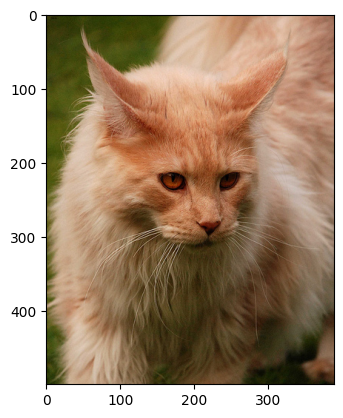

In [ ]:
idx = 0
sample = dataset['train'][idx]
print(sample.keys())

image = sample['image']
plt.imshow(image)
plt.show()


In [ ]:
from torchvision import transforms

In [ ]:
from torchvision import transforms

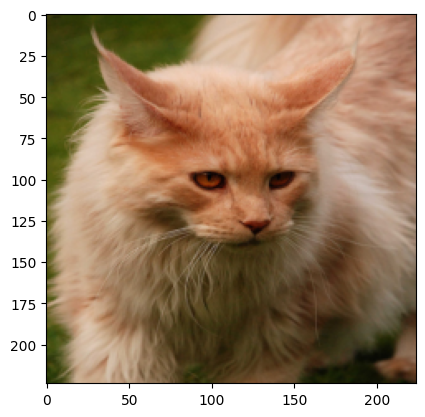

In [ ]:
size = (224, 224)
image_resize = transforms.Resize(size)(image)
plt.imshow(image_resize)
plt.show()

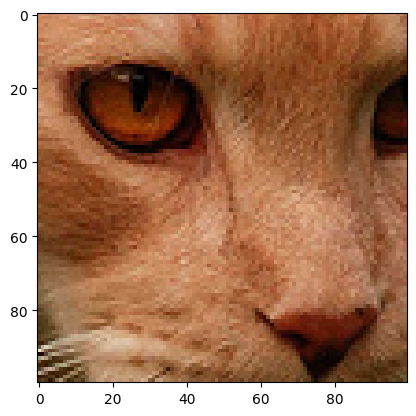

In [ ]:
size = 100
image_ceter_crop = transforms.CenterCrop(size)(image)
plt.imshow(image_ceter_crop)
plt.show()

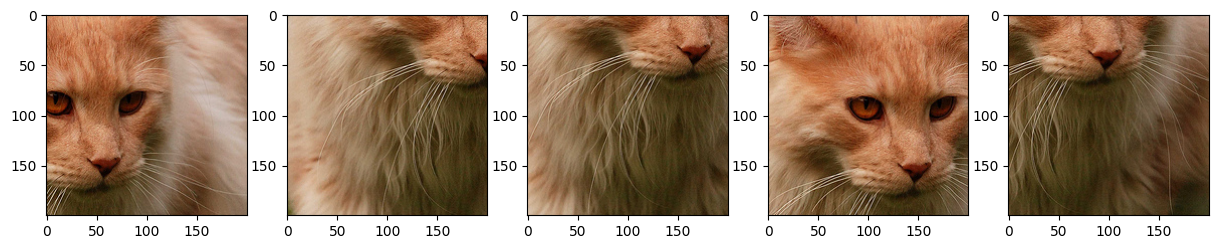

In [ ]:
size = 200
num_samples = 5
plt.figure(figsize=(15,10))
for i in range(num_samples):
    image_random_crop = transforms.RandomCrop(size)(image)
    plt.subplot(1, num_samples, i+1)
    plt.imshow(image_random_crop)
plt.show()

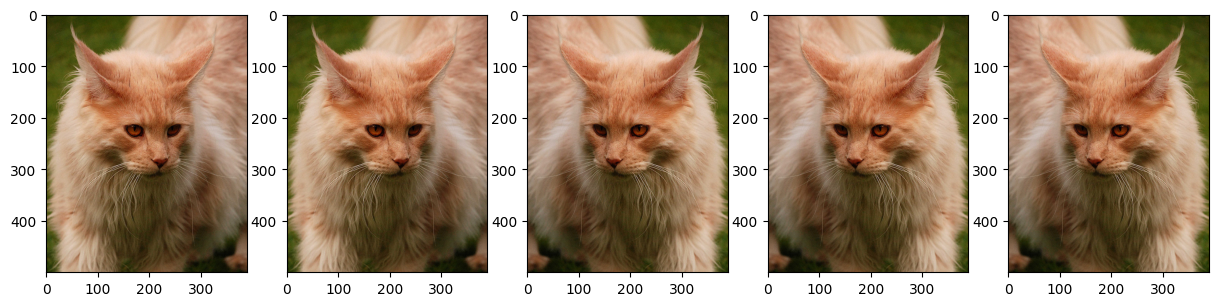

In [ ]:
prob_to_flip = 0.5
num_samples =5
plt.figure(figsize=(15, 10))

for i in range(num_samples):
    image_random_horizontal_flip = transforms.RandomHorizontalFlip(prob_to_flip)(image)
    plt.subplot(1, num_samples, i+1)
    plt.imshow(image_random_horizontal_flip)
plt.show()

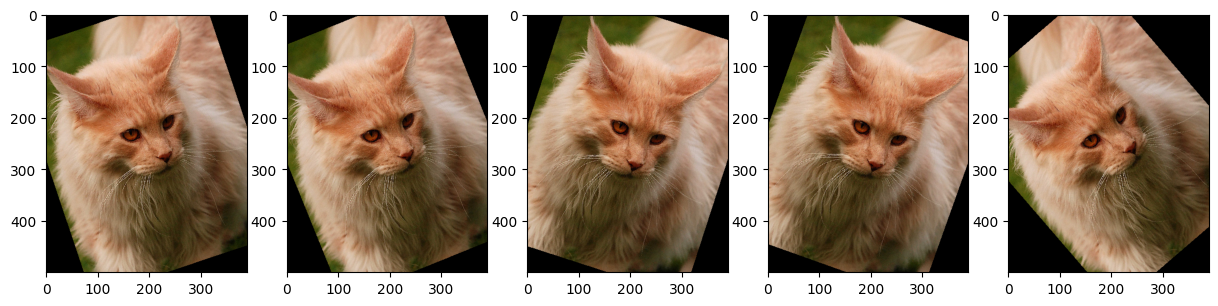

In [ ]:
angle_range = (-30, 60)
num_samples = 5
plt.figure(figsize=(15,10))
for i in range(num_samples):
    image_random_angle_range = transforms.RandomRotation(angle_range)(image)
    plt.subplot(1, num_samples, i+1)
    plt.imshow(image_random_angle_range)
plt.show()

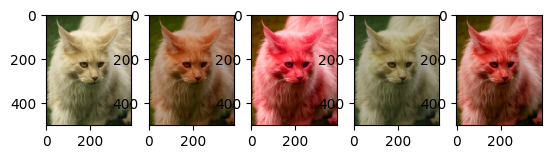

In [ ]:
color_jitter = transforms.ColorJitter(brightness= 0.2, contrast=0.3, saturation = 0.4, hue=0.1)


for i in range(num_samples):
    color_jitter = transforms.ColorJitter(brightness= 0.2, contrast=0.3, saturation = 0.4, hue=0.1)
    image_random_color_jitter = color_jitter(image)
    plt.subplot(1, num_samples, i+1)
    plt.imshow(image_random_color_jitter)
plt.show()

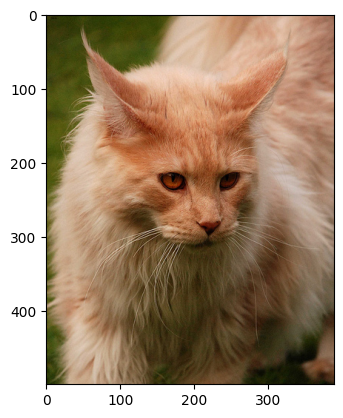

'\nfor i in range(num_samples):\n    blur = transforms.GaussianBlur(\n        kernel_size=5,\n        sigma=(30.7, 50.3)\n    )\n    image_blur = blur(image)\n    plt.subplot(1, num_samples, i+1)\n    plt.imshow(image_blur)\nplt.show()\n'

In [ ]:
blur = transforms.GaussianBlur(
    kernel_size=1,
    sigma=(30.7, 50.3)
)
image_blur = blur(image)
plt.imshow(image_blur)
plt.show()

"""
for i in range(num_samples):
    blur = transforms.GaussianBlur(
        kernel_size=5,
        sigma=(30.7, 50.3)
    )
    image_blur = blur(image)
    plt.subplot(1, num_samples, i+1)
    plt.imshow(image_blur)
plt.show()
"""

In [ ]:
image_tensor = transforms.ToTensor()(image)

print(type(image))
print(type(image_tensor))


<class 'PIL.JpegImagePlugin.JpegImageFile'>
<class 'torch.Tensor'>


In [ ]:
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]
image_tensor_norm = transforms. Normalize(mean,std)(image_tensor)

print(image_tensor_norm)

tensor([[[-0.9020, -0.9363, -1.0733,  ...,  0.7419,  0.7591,  0.8276],
         [-1.0219, -1.0390, -1.1075,  ...,  0.8104,  0.7077,  0.6563],
         [-1.0390, -1.0048, -1.0733,  ...,  0.6734,  0.6221,  0.6049],
         ...,
         [-1.6042, -1.5014, -1.5528,  ..., -1.1589, -1.0562, -1.0733],
         [-1.5357, -1.6384, -1.4672,  ..., -1.3130, -1.2274, -1.2274],
         [-1.5870, -1.5185, -1.4158,  ..., -1.4843, -1.4329, -1.4158]],

        [[-0.8277, -0.8627, -1.0203,  ..., -0.0224, -0.0049,  0.0126],
         [-0.9328, -0.9503, -1.0203,  ...,  0.0476, -0.0574, -0.1099],
         [-0.9153, -0.8803, -1.0028,  ..., -0.0749, -0.1450, -0.1625],
         ...,
         [-1.2479, -1.1429, -1.1954,  ..., -1.3529, -1.2654, -1.2829],
         [-1.1779, -1.2829, -1.0903,  ..., -1.4055, -1.3529, -1.3529],
         [-1.2304, -1.1604, -1.0378,  ..., -1.5280, -1.4755, -1.4580]],

        [[-1.4559, -1.4733, -1.5779,  ..., -0.1661, -0.1487, -0.1138],
         [-1.5081, -1.4907, -1.5604,  ..., -0

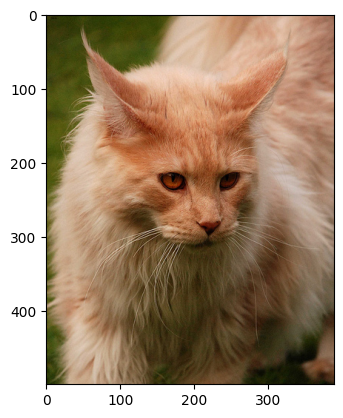

In [ ]:
transformation = transforms.Lambda(lambda image: image.convert('RGBA'))

new_image = transformation(image)
plt.imshow(new_image)
plt.show()

In [ ]:
size = (224, 224)
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]
transform = transforms.Compose(
    [
        transforms.Lambda(lambda image: image.convert('RGB'))
        transforms.Resize(size),
        transforms.ToTensor(),
        transforms.Normalize(mean, std)
    ]
)
image_tensors_list = transform(data)
print(image_tensor.shape)

print(image_tensor)

torch.Size([3, 224, 224])
tensor([[[-0.9877, -1.0562, -1.0048,  ...,  0.7591,  0.7591,  0.7077],
         [-1.0390, -1.0390, -1.0562,  ...,  0.6049,  0.5536,  0.5364],
         [-1.0904, -1.1075, -1.1075,  ...,  0.5364,  0.4851,  0.4337],
         ...,
         [-1.5357, -1.5185, -1.3815,  ..., -0.8507, -0.7308, -0.7137],
         [-1.5528, -1.5014, -1.3473,  ..., -1.1247, -1.0219, -0.9192],
         [-1.5528, -1.4843, -1.3815,  ..., -1.3815, -1.3302, -1.2788]],

        [[-0.8978, -0.9853, -0.9853,  ...,  0.0301, -0.0049, -0.0574],
         [-0.9153, -0.9678, -1.0028,  ..., -0.1099, -0.1800, -0.2150],
         [-1.0203, -1.0203, -1.0203,  ..., -0.1625, -0.2150, -0.2325],
         ...,
         [-1.1779, -1.1954, -1.0728,  ..., -1.1954, -1.1429, -1.1429],
         [-1.2129, -1.1779, -1.0378,  ..., -1.3179, -1.2654, -1.2129],
         [-1.1954, -1.1078, -0.9853,  ..., -1.4405, -1.4230, -1.3880]],

        [[-1.4733, -1.5256, -1.5430,  ..., -0.1312, -0.1487, -0.2010],
         [-1.4907, 

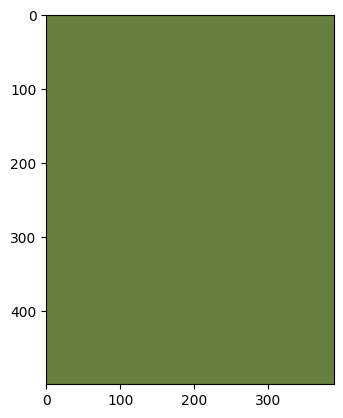

In [ ]:
image_tensor = transforms.ToTensor()(image)

new_image = transforms.ToPILImage()(image_tensor)

plt.imshow(new_image)
plt.show()

In [ ]:
num_images = len(dataset['train'])
print(num)